# 实验三：Seaborn 与 Pyecharts 综合绘图实践

2025311525　刘孝伟

In [ ]:
from pathlib import Path
import re
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML, Image
from pyecharts import options as opts
from pyecharts.charts import Line, Bar, Pie, Scatter, Page
from pyecharts.globals import ThemeType, CurrentConfig

# 固定 ECharts 5 资源版本，与提交 HTML 内嵌的运行库保持一致。
CurrentConfig.ONLINE_HOST = 'https://assets.pyecharts.org/assets/v5/'

OUT = Path.cwd()
paths = [OUT / 'nuannuan_2025.csv', OUT.parent / 'nuannuan_2025.csv',
         OUT.parent.parent / 'nuannuan_2025.csv']
DATA = next((p for p in paths if p.is_file()), None)
if DATA is None:
    raise FileNotFoundError('请将 nuannuan_2025.csv 放在 notebook 同目录后重跑。')
df = pd.read_csv(DATA, encoding='utf-8-sig', parse_dates=['日期'])
assert df.shape == (2920, 13), '核对是否使用了正确的数据'
assert not df.isna().any().any(), '发现缺失值'
assert not df.duplicated(['日期', '门店']).any(), '同日同店有重复记录'
assert df['日期'].nunique() == 365 and df['门店'].nunique() == 8
assert df.groupby('门店').size().eq(365).all()
assert df['日期'].dt.year.eq(2025).all()
assert df['月份'].eq(df['日期'].dt.month).all()

NAVY, BLUE, AMBER = '#1E3A8A', '#2563EB', '#F59E0B'
REGION_COLORS = {'城区': BLUE, '文教区': '#10B981', '新城': AMBER, '枢纽': '#8B5CF6'}
# 各区域门店数量不等，区域总额不能直接当作单店效率。
regions = list(REGION_COLORS)
stores = df['门店'].drop_duplicates().tolist()
CATEGORY_COLORS = {'咖啡': BLUE, '甜品': AMBER, '轻食': '#10B981', '周边': '#8B5CF6'}
sns.set_theme(style='whitegrid', palette=list(REGION_COLORS.values()))
plt.rcParams.update({'font.sans-serif': ['Microsoft YaHei', 'SimHei'],
                     'axes.unicode_minus': False, 'figure.dpi': 110,
                     'axes.titlesize': 13, 'axes.titleweight': 'bold',
                     'axes.titlecolor': NAVY})

def finish(fig, ax, title, xlabel, ylabel, name):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(linestyle='--', alpha=.3)
    fig.tight_layout()
    fig.savefig(OUT / name, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# 将依赖嵌入 HTML；已有成品可作为离线依赖缓存，不需要额外交付 JS 文件。
asset_cache = {}
def offline_html(document):
    for old in OUT.glob('*.html'):
        for url, script in re.findall(r'<script data-offline-src="([^"]+)">(.*?)</script>',
                                      old.read_text(encoding='utf-8'), re.S):
            asset_cache.setdefault(url, script)
        if len(asset_cache) >= 2:
            break
    def replace(match):
        url = match.group(1)
        if url not in asset_cache:
            with urlopen(url, timeout=60) as response:
                asset_cache[url] = response.read().decode('utf-8')
        script = asset_cache[url].replace('</script', r'<\/script')
        return '<script data-offline-src="' + url + '">' + script + '</script>'
    return re.sub(r'<script[^>]+src="([^"]+)"[^>]*>\s*</script>', replace, document)

def init(title, width='1080px', height='500px'):
    return opts.InitOpts(theme=ThemeType.ROMA, width=width, height=height,
                         page_title=title, bg_color='#FFFFFF',
                         animation_opts=opts.AnimationOpts(animation=False))

def export_chart(chart, filename):
    path = OUT / filename
    chart.options['textStyle'] = {'fontFamily': 'Microsoft YaHei', 'color': NAVY}
    if chart.options['series'][0]['type'] in ['line', 'bar', 'scatter']:
        chart.options['grid'] = {'left': '10%', 'right': '6%', 'top': '24%', 'bottom': '18%'}
    path.write_text(offline_html(chart.render_embed()), encoding='utf-8')
    # 显示实际图表配置的文字摘要；已归档 PNG 由浏览器真实渲染而来。
    if hasattr(chart, 'options'):
        print(filename, '：', ', '.join(s['name'] or '品类' for s in chart.options['series']))
    display(HTML(f'<a href="{filename}" target="_blank">打开交互结果：{filename}</a>'))
    snapshot = path.with_suffix('.png')
    if snapshot.exists():
        display(Image(filename=str(snapshot), width=1000))

region_stats = df.groupby('区域')['销售额'].agg(['count', 'mean', 'std', 'sum']).reindex(regions)
season_stats = df.groupby('季节')['销售额'].agg(['count', 'mean', 'sum']).reindex(['春','夏','秋','冬'])
monthly = df.groupby(['月份', '区域'])['销售额'].sum().unstack().reindex(index=range(1,13), columns=regions)
store_sales = df.groupby('门店')['销售额'].sum().reindex(stores)
category_sales = df.groupby('主推品类')['销售额'].sum().reindex(CATEGORY_COLORS)
cols = ['销售额', '订单数', '客单价', '气温', '会员订单占比']
corr = df[cols].corr()
print(f'数据：{len(df)} 行，{df.shape[1]} 列；8 家门店 × 365 天；缺失值 0，重复门店日期 0。')
print(f'全年总销售额：{df["销售额"].sum():,.2f} 元。')
display(df.head())

数据：2920 行，13 列；8 家门店 × 365 天；缺失值 0，重复门店日期 0。
全年总销售额：21,699,238.60 元。


,日期,门店,区域,主推品类,月份,季节,天气,气温,是否促销,销售额,订单数,会员订单占比,客单价
0,2025-01-01,中央店,城区,咖啡,1,冬,晴,5.4,否,5221.0,100,0.356,52.21
1,2025-01-01,江滨店,城区,甜品,1,冬,晴,-3.2,否,2983.9,68,0.421,43.88
2,2025-01-01,老街店,城区,轻食,1,冬,晴,-3.2,否,4197.5,91,0.395,46.13
3,2025-01-01,大学城店,文教区,咖啡,1,冬,晴,-3.2,否,4887.6,117,0.332,41.77
4,2025-01-01,高新店,文教区,周边,1,冬,晴,-0.9,否,5154.5,125,0.296,41.24


## T1　各区域门店日销售额分布

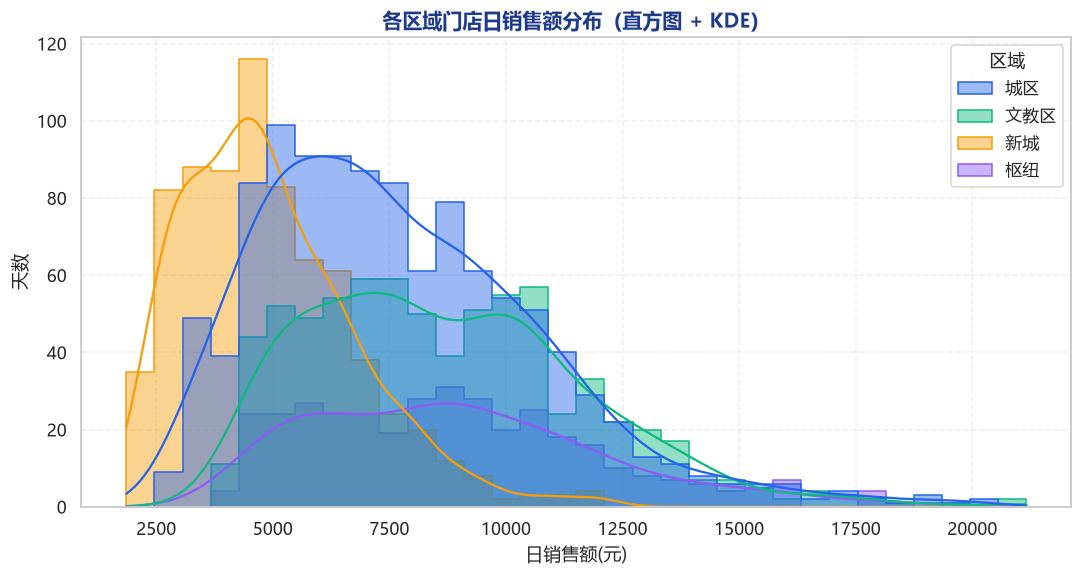

,count,mean,std,sum
区域,,,,
城区,1095,7757.94,3025.55,8494946.7
文教区,730,8716.69,2965.87,6363186.0
新城,730,4911.21,1844.76,3585180.3
枢纽,365,8920.34,3118.84,3255925.6


In [2]:
fig, ax = plt.subplots(figsize=(10, 5.4))
sns.histplot(data=df, x='销售额', hue='区域', hue_order=regions,
             palette=REGION_COLORS, bins=32, kde=True, element='step',
             fill=True, alpha=.45, ax=ax)
finish(fig, ax, '各区域门店日销售额分布（直方图 + KDE）',
       '日销售额(元)', '天数', 't1_distribution.png')
display(region_stats.round(2))

### T1 简要分析
枢纽区域日均销售额最高（8,920.34 元），文教区次之（8,716.69 元），新城最低（4,911.21 元）。枢纽标准差为 3,118.84 元，在四区中最大，日销售额波动较宽；新城标准差为 1,844.76 元，相对较窄。直方图纵轴按要求标“天数”，其实际计数单位是“门店日记录”：城区、文教区、新城、枢纽分别包含 3、2、2、1 家店，样本数不同，不能用直方图高度直接比较单店业绩，应结合分布位置和表中日均值。

## T2　各门店日销售额分布小提琴图

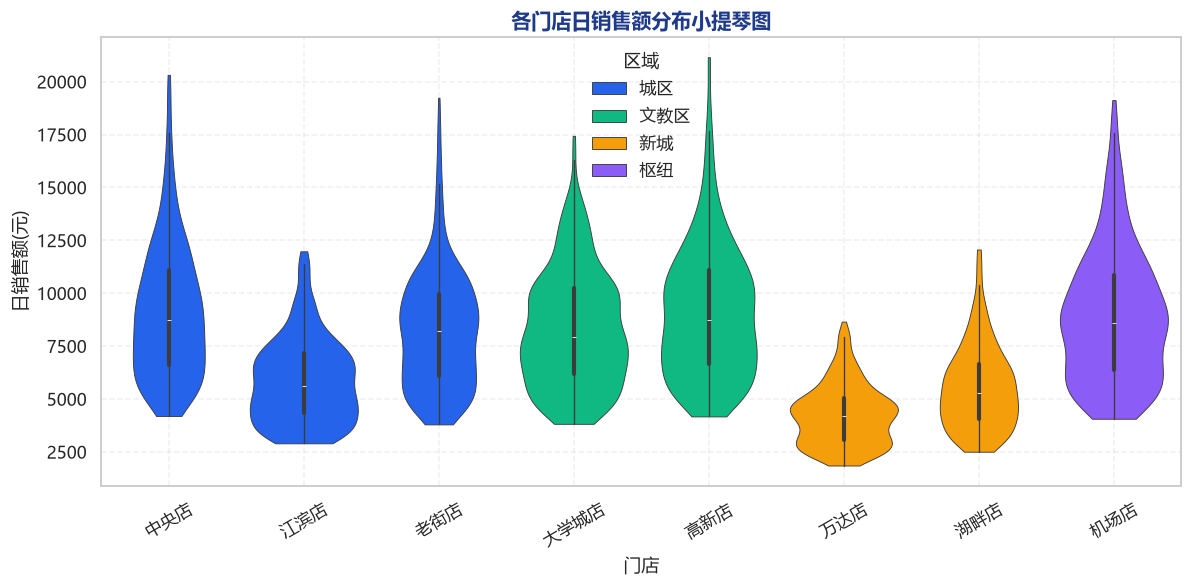

,mean,median,std
门店,,,
中央店,9139.95,8749.9,3174.31
江滨店,5873.09,5612.8,2004.09
老街店,8260.79,8223.5,2772.81
大学城店,8302.55,7937.8,2740.78
高新店,9130.83,8740.6,3124.29
万达店,4255.95,4196.1,1435.87
湖畔店,5566.46,5303.0,1973.01
机场店,8920.34,8604.2,3118.84


In [3]:
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.violinplot(data=df, x='门店', y='销售额', hue='区域', order=stores,
               hue_order=regions, palette=REGION_COLORS, cut=0,
               inner='box', linewidth=.6, dodge=False, saturation=1, ax=ax)
ax.tick_params(axis='x', labelrotation=30)
ax.legend(title='区域', frameon=False)
finish(fig, ax, '各门店日销售额分布小提琴图', '门店', '日销售额(元)', 't2_violin.png')
display(df.groupby('门店')['销售额'].agg(['mean', 'median', 'std']).reindex(stores).round(2))

### T2 简要分析
中央店（9,139.95 元/日）与高新店（9,130.83 元/日）均值接近、处于较高水平；万达店（4,255.95 元/日）偏低。小提琴的横向宽度表示某一销售额附近的密度，不是销售总额；内嵌箱体展示四分位位置，不能把箱内线直接称为均值。小提琴适合看偏态、多峰和分布形状；箱线图更适合简洁比较中位数、四分位距及异常值。`cut=0` 避免密度曲线延伸至实际极值之外。

## T3　气温与日销售额关系（含回归线）

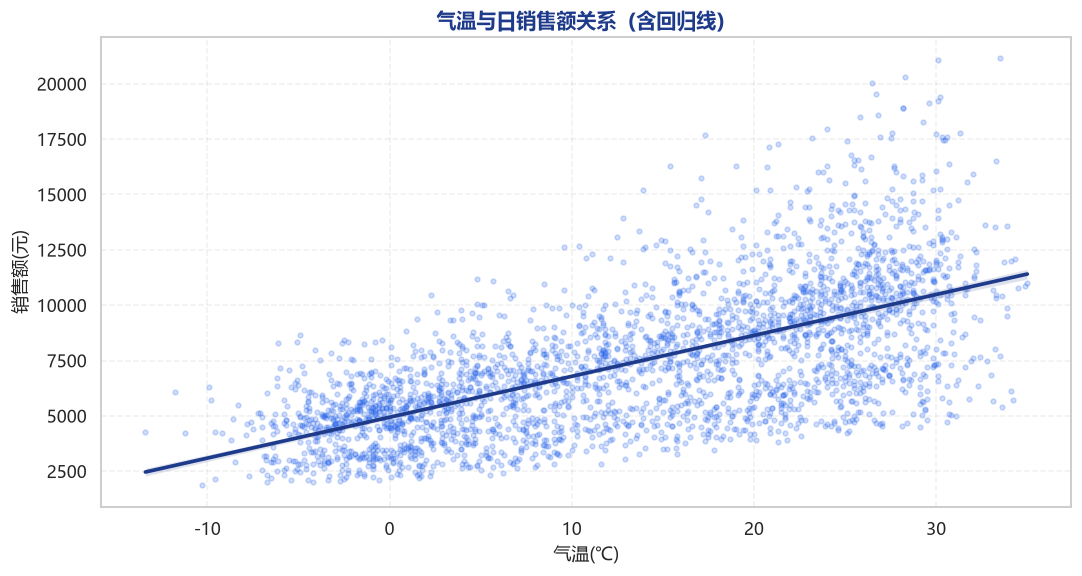

拟合直线：销售额 = 4939.58 + 184.79 × 气温
Pearson r = 0.6509


In [4]:
fig, ax = plt.subplots(figsize=(10, 5.4))
sns.regplot(data=df, x='气温', y='销售额', seed=42,
            scatter_kws={'s': 10, 'alpha': .22, 'color': BLUE},
            line_kws={'color': NAVY, 'lw': 2.4}, ax=ax)
finish(fig, ax, '气温与日销售额关系（含回归线）', '气温(℃)', '销售额(元)', 't3_regression.png')
slope, intercept = np.polyfit(df['气温'], df['销售额'], 1)
print(f'拟合直线：销售额 = {intercept:.2f} + {slope:.2f} × 气温')
print(f'Pearson r = {corr.loc["气温", "销售额"]:.4f}')

### T3 简要分析
回归斜率约为 +184.79 元/℃，Pearson 相关系数为 0.6509，说明该样本中气温与日销售额总体呈正向线性关系，方向上符合高温时消费更旺的直觉。但 CSV 记录的是门店全部销售额，不是冷饮销量，不能据此断定“冷饮带动销售”。季节、门店与促销可能共同作用。

## T4　数值变量相关系数热力图

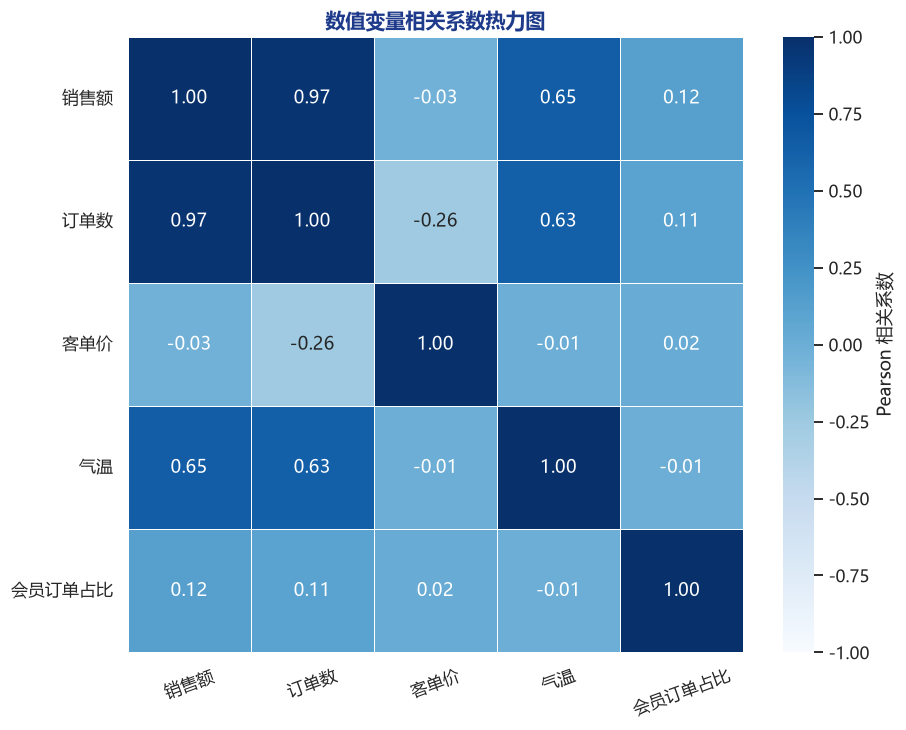

,销售额,订单数,客单价,气温,会员订单占比
销售额,1.0000,0.9657,-0.0264,0.6509,0.1172
订单数,0.9657,1.0000,-0.2571,0.6266,0.1069
客单价,-0.0264,-0.2571,1.0000,-0.0077,0.0175
气温,0.6509,0.6266,-0.0077,1.0000,-0.0061
会员订单占比,0.1172,0.1069,0.0175,-0.0061,1.0000


In [5]:
fig, ax = plt.subplots(figsize=(8.6, 6.8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', square=True,
            vmin=-1, vmax=1, linewidths=.5, ax=ax,
            cbar_kws={'label': 'Pearson 相关系数'})
ax.set_title('数值变量相关系数热力图')
ax.tick_params(axis='x', labelrotation=20)
ax.tick_params(axis='y', labelrotation=0)
fig.tight_layout()
fig.savefig(OUT / 't4_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)
display(corr.round(4))

### T4 简要分析
除对角线和重复的对称项外，按相关系数绝对值排序，最强的两对是销售额—订单数（0.9657）和销售额—气温（0.6509）；订单数—气温紧随其后（0.6266）。客单价与销售额的线性相关很弱（−0.0264），会员订单占比与销售额也较弱（0.1172），但弱相关不等于变量相互独立。销售额、订单数和客单价存在业务计算联系，相关系数不能说明因果，也不宜将统计关联全部归因于营销。依题设采用 `Blues` 并固定 −1～1 色标，判断正负应读取格内数字。

## T5　各区域月度销售额趋势（可缩放）

p1_line.html ： 城区, 文教区, 新城, 枢纽


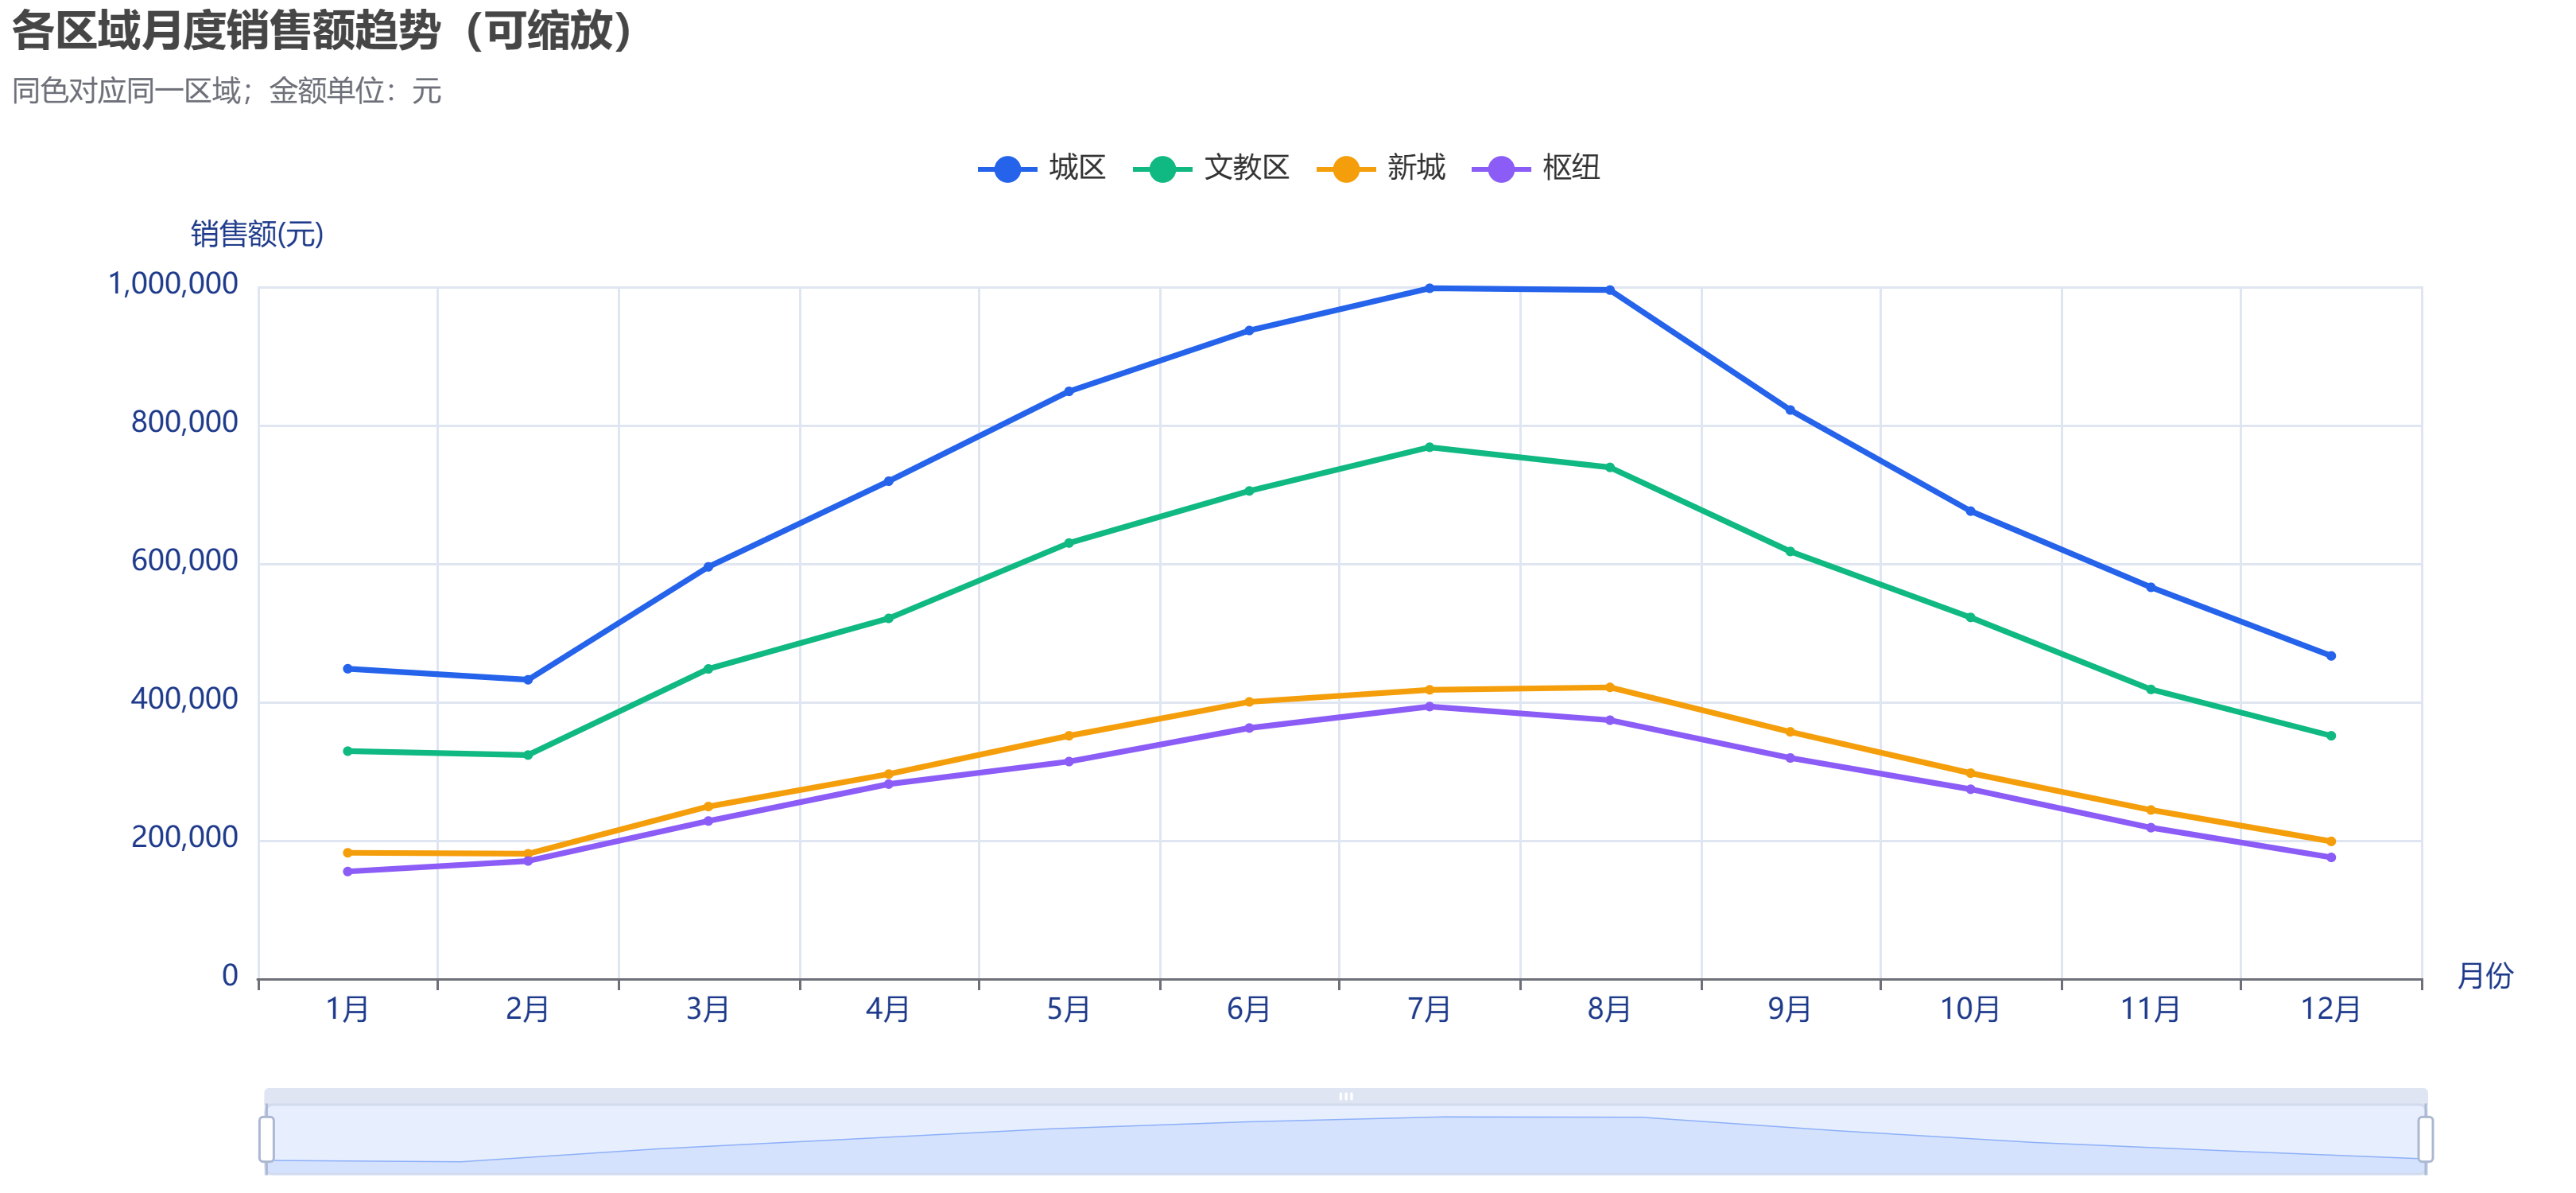

区域,城区,文教区,新城,枢纽
月份,,,,
1,447347.2,328234.7,181335.2,154278.4
2,431394.6,322601.9,179935.0,169490.5
3,594562.2,447055.4,248180.9,227263.2
4,718349.3,520117.1,295050.9,280602.6
5,848164.2,629002.1,350435.8,313166.5
6,936161.6,704247.2,399422.3,361640.0
7,997185.7,767439.8,416850.2,392653.1
8,994578.9,738327.2,420430.4,372969.4
9,821228.3,616807.0,356119.0,318371.8


In [6]:
line = Line(init_opts=init('月度销售趋势'))
line.add_xaxis([f'{m}月' for m in monthly.index])
for rg in regions:
    line.add_yaxis(rg, monthly[rg].round(2).tolist(), symbol='circle',
                   color=REGION_COLORS[rg], is_symbol_show=True,
                   label_opts=opts.LabelOpts(is_show=False),
                   linestyle_opts=opts.LineStyleOpts(width=2.4))
line.set_global_opts(
    title_opts=opts.TitleOpts(title='各区域月度销售额趋势（可缩放）',
                              subtitle='同色对应同一区域；金额单位：元'),
    legend_opts=opts.LegendOpts(pos_top='12%', textstyle_opts=opts.TextStyleOpts(font_family='Microsoft YaHei')),
    tooltip_opts=opts.TooltipOpts(trigger='axis'),
    datazoom_opts=[opts.DataZoomOpts(type_='slider', range_start=0, range_end=100),
                   opts.DataZoomOpts(type_='inside')],
    xaxis_opts=opts.AxisOpts(name='月份'),
    yaxis_opts=opts.AxisOpts(name='销售额(元)', axislabel_opts=opts.LabelOpts(formatter='{value}')))
export_chart(line, 'p1_line.html')
display(monthly.round(2))

### T5 简要分析
全店月总额在 7 月达到 2,574,128.80 元，6–8 月是旺季。城区、文教区、枢纽的峰值在 7 月，新城在 8 月，各区总体呈夏高冬低但峰值不完全同步。城区总额最高并不意味着单店最强，因为其门店数最多；月总额还受月份天数影响。拖动底部 DataZoom 可聚焦局部月份，悬停可对比同月各区域，点击图例可隐藏系列，减少折线重叠。

## T6　门店全年销售额（标签与最高值标记）

p2_bar.html ： 总销售额


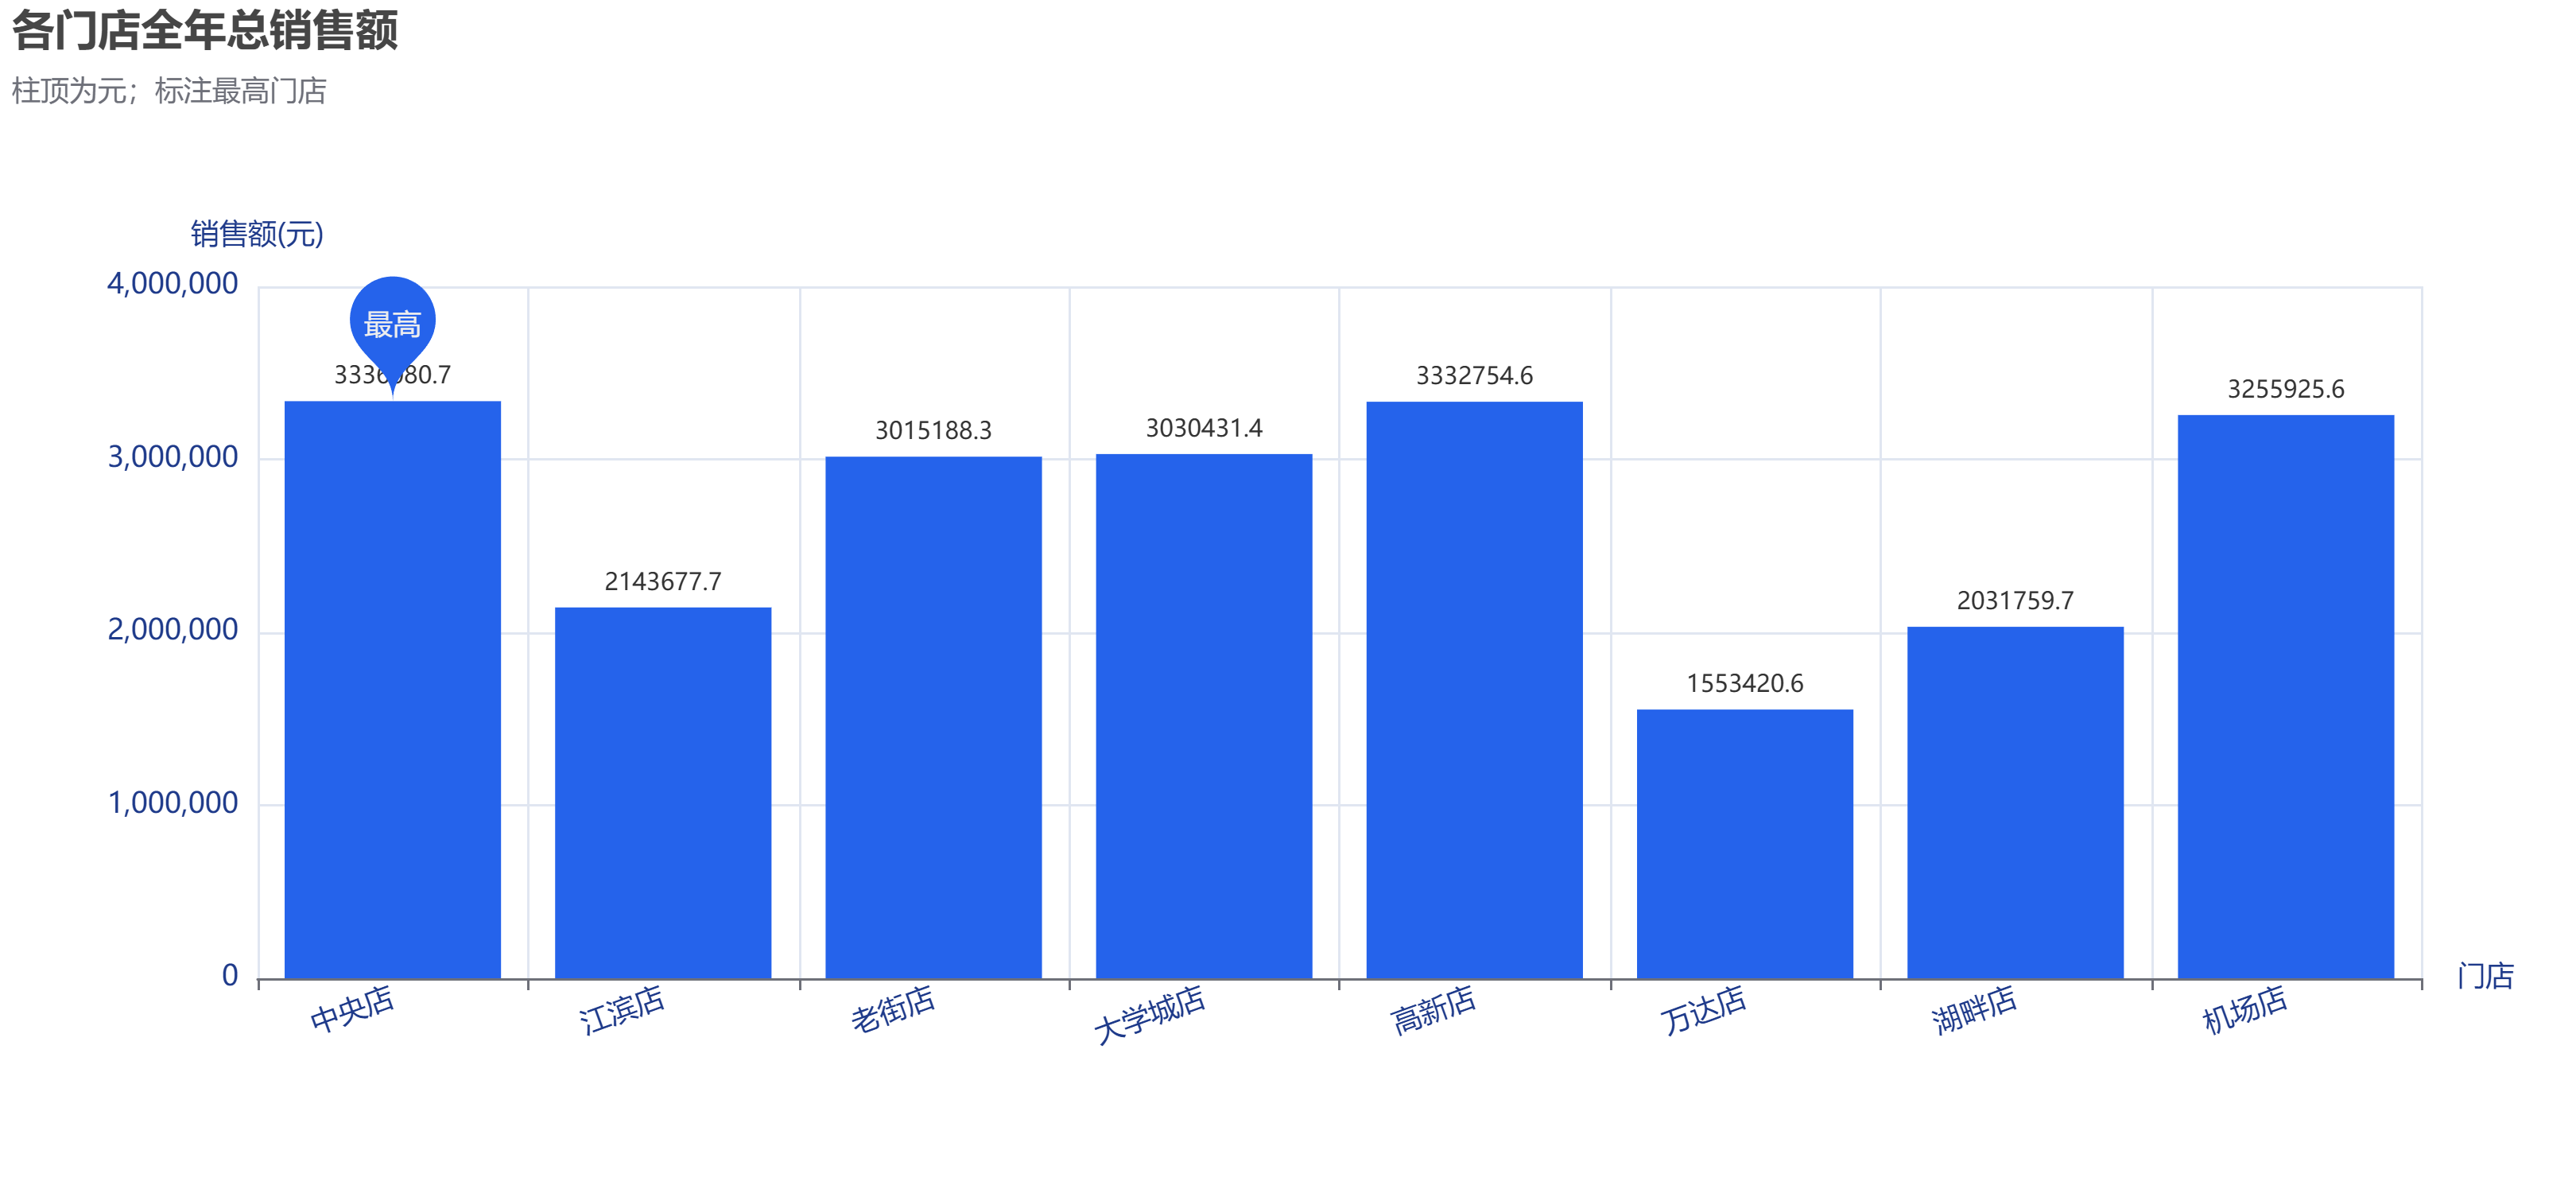

,全年销售额(元)
门店,
中央店,3336080.7
高新店,3332754.6
机场店,3255925.6
大学城店,3030431.4
老街店,3015188.3
江滨店,2143677.7
湖畔店,2031759.7
万达店,1553420.6


In [7]:
bar = Bar(init_opts=init('门店销售额'))
bar.add_xaxis(store_sales.index.tolist())
bar.add_yaxis('总销售额', store_sales.round(2).tolist(), color=BLUE,
              label_opts=opts.LabelOpts(is_show=True, position='top',
                                        formatter='{c}', font_size=10),
              markpoint_opts=opts.MarkPointOpts(data=[opts.MarkPointItem(type_='max', name='最高')],
                                                symbol_size=60, label_opts=opts.LabelOpts(formatter='{b}')))
bar.set_global_opts(
    title_opts=opts.TitleOpts(title='各门店全年总销售额', subtitle='柱顶为元；标注最高门店'),
    legend_opts=opts.LegendOpts(is_show=False),
    tooltip_opts=opts.TooltipOpts(trigger='axis'),
    xaxis_opts=opts.AxisOpts(name='门店', axislabel_opts=opts.LabelOpts(rotate=20)),
    yaxis_opts=opts.AxisOpts(name='销售额(元)', max_=4000000))
export_chart(bar, 'p2_bar.html')
display(store_sales.sort_values(ascending=False).round(2).to_frame('全年销售额(元)'))

### T6 简要分析
中央店全年销售额 3,336,080.70 元，略高于高新店的 3,332,754.60 元，仅差 3,326.10 元（约占中央店总额 0.10%），不能把两者描述为明显拉开差距。各店均为 365 条日记录，全年总额排名与日均值排名完全一致，因此与 T2 中中央店、高新店分布位置偏高相呼应；但总额最高并不保证中位数也最高。最高值标记用于快速定位，悬停可读取精确数值。

## T7　主推品类销售额占比圆环图

p3_pie.html ： 品类


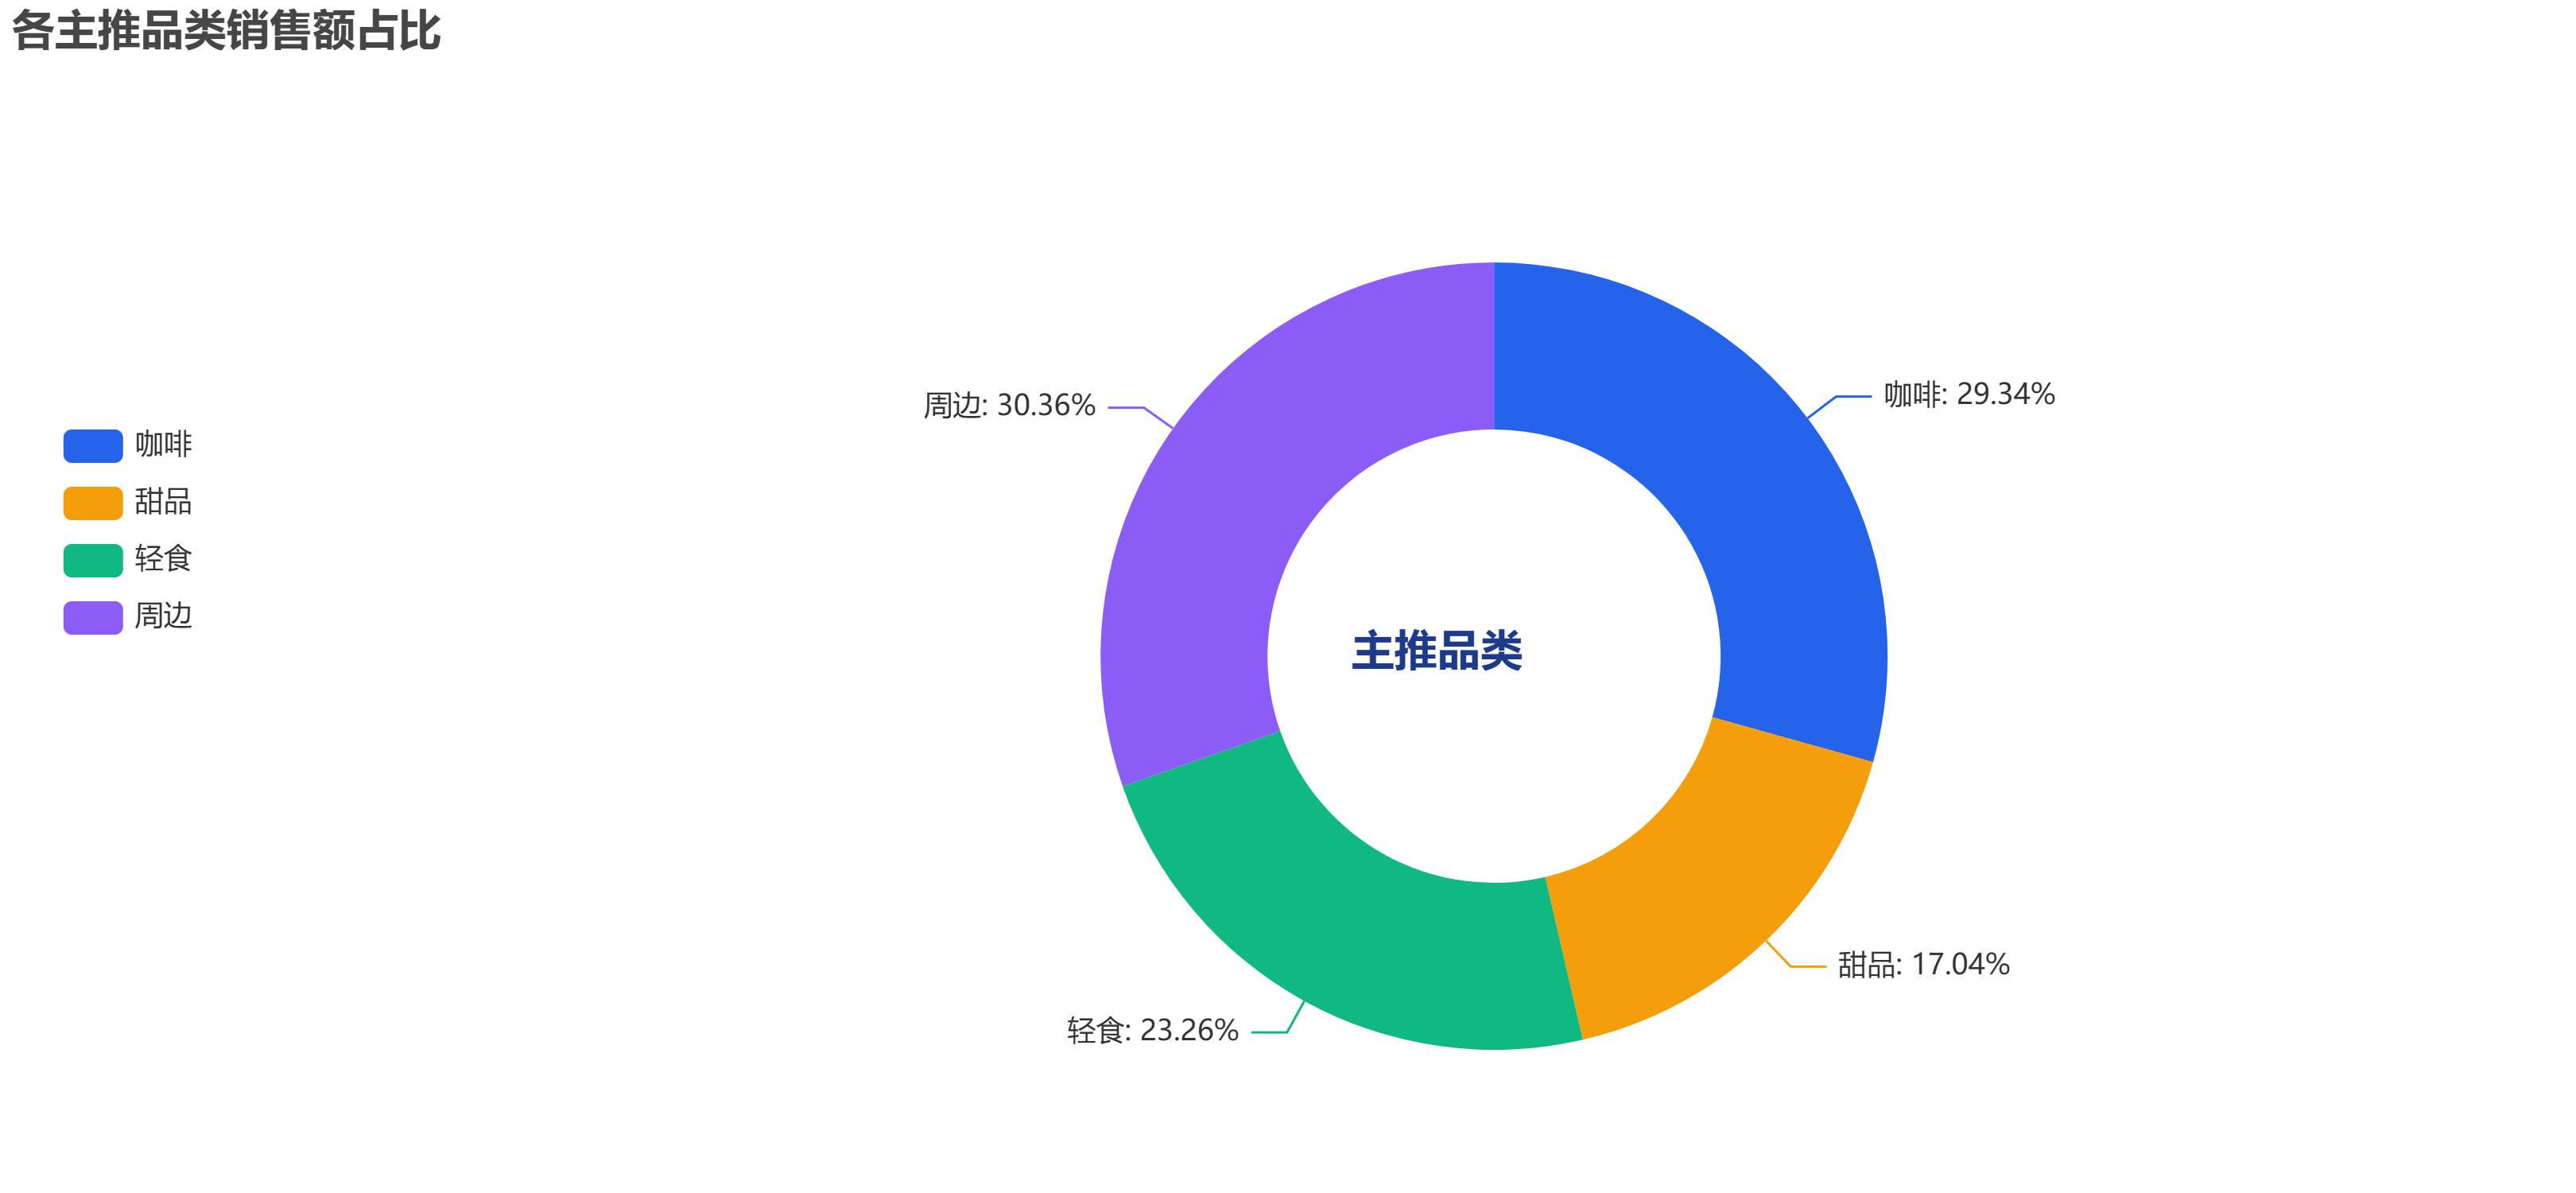

,销售额(元),占比(%)
主推品类,,
咖啡,6366512.1,29.34
甜品,3697098.3,17.04
轻食,5046948.0,23.26
周边,6588680.2,30.36


In [8]:
pie = Pie(init_opts=init('主推品类占比'))
pie.add('品类', [(str(k), float(v)) for k, v in category_sales.items()],
         radius=['38%', '66%'], center=['58%', '55%'],
         label_opts=opts.LabelOpts(is_show=True, formatter='{b}: {d}%'))
pie.set_colors(list(CATEGORY_COLORS.values()))
pie.set_global_opts(
    title_opts=opts.TitleOpts(title='各主推品类销售额占比'),
    legend_opts=opts.LegendOpts(orient='vertical', pos_left='2%', pos_top='35%'),
    tooltip_opts=opts.TooltipOpts(trigger='item', formatter='{b}<br/>{c} 元（{d}%）'))
# 添加圆环中心标题，保留主标题。
pie.options['title'] = pie.options['title'].opts + opts.TitleOpts(title='主推品类', pos_left='52%', pos_top='52%',
    title_textstyle_opts=opts.TextStyleOpts(color=NAVY, font_size=18)).opts
export_chart(pie, 'p3_pie.html')
display(pd.DataFrame({'销售额(元)': category_sales,
                       '占比(%)': category_sales / category_sales.sum() * 100}).round(2))

### T7 简要分析
按“主推品类”属性归组，周边占 30.36%，咖啡占 29.34%，轻食占 23.26%，甜品占 17.04%。每家门店的主推品类固定，因此这里是“主推该品类的门店销售额份额”，不是商品明细层面的真实品类收入份额，不能据此直接推出各产品销量。圆环中央留白能放置不遮挡扇区的主题文字；图例可以切换类别显隐，显示范围改变后应重新留意百分比所代表的可见合计。

## T8　气温—销售额交互散点图（按促销分组）

p4_scatter.html ： 促销日, 非促销日


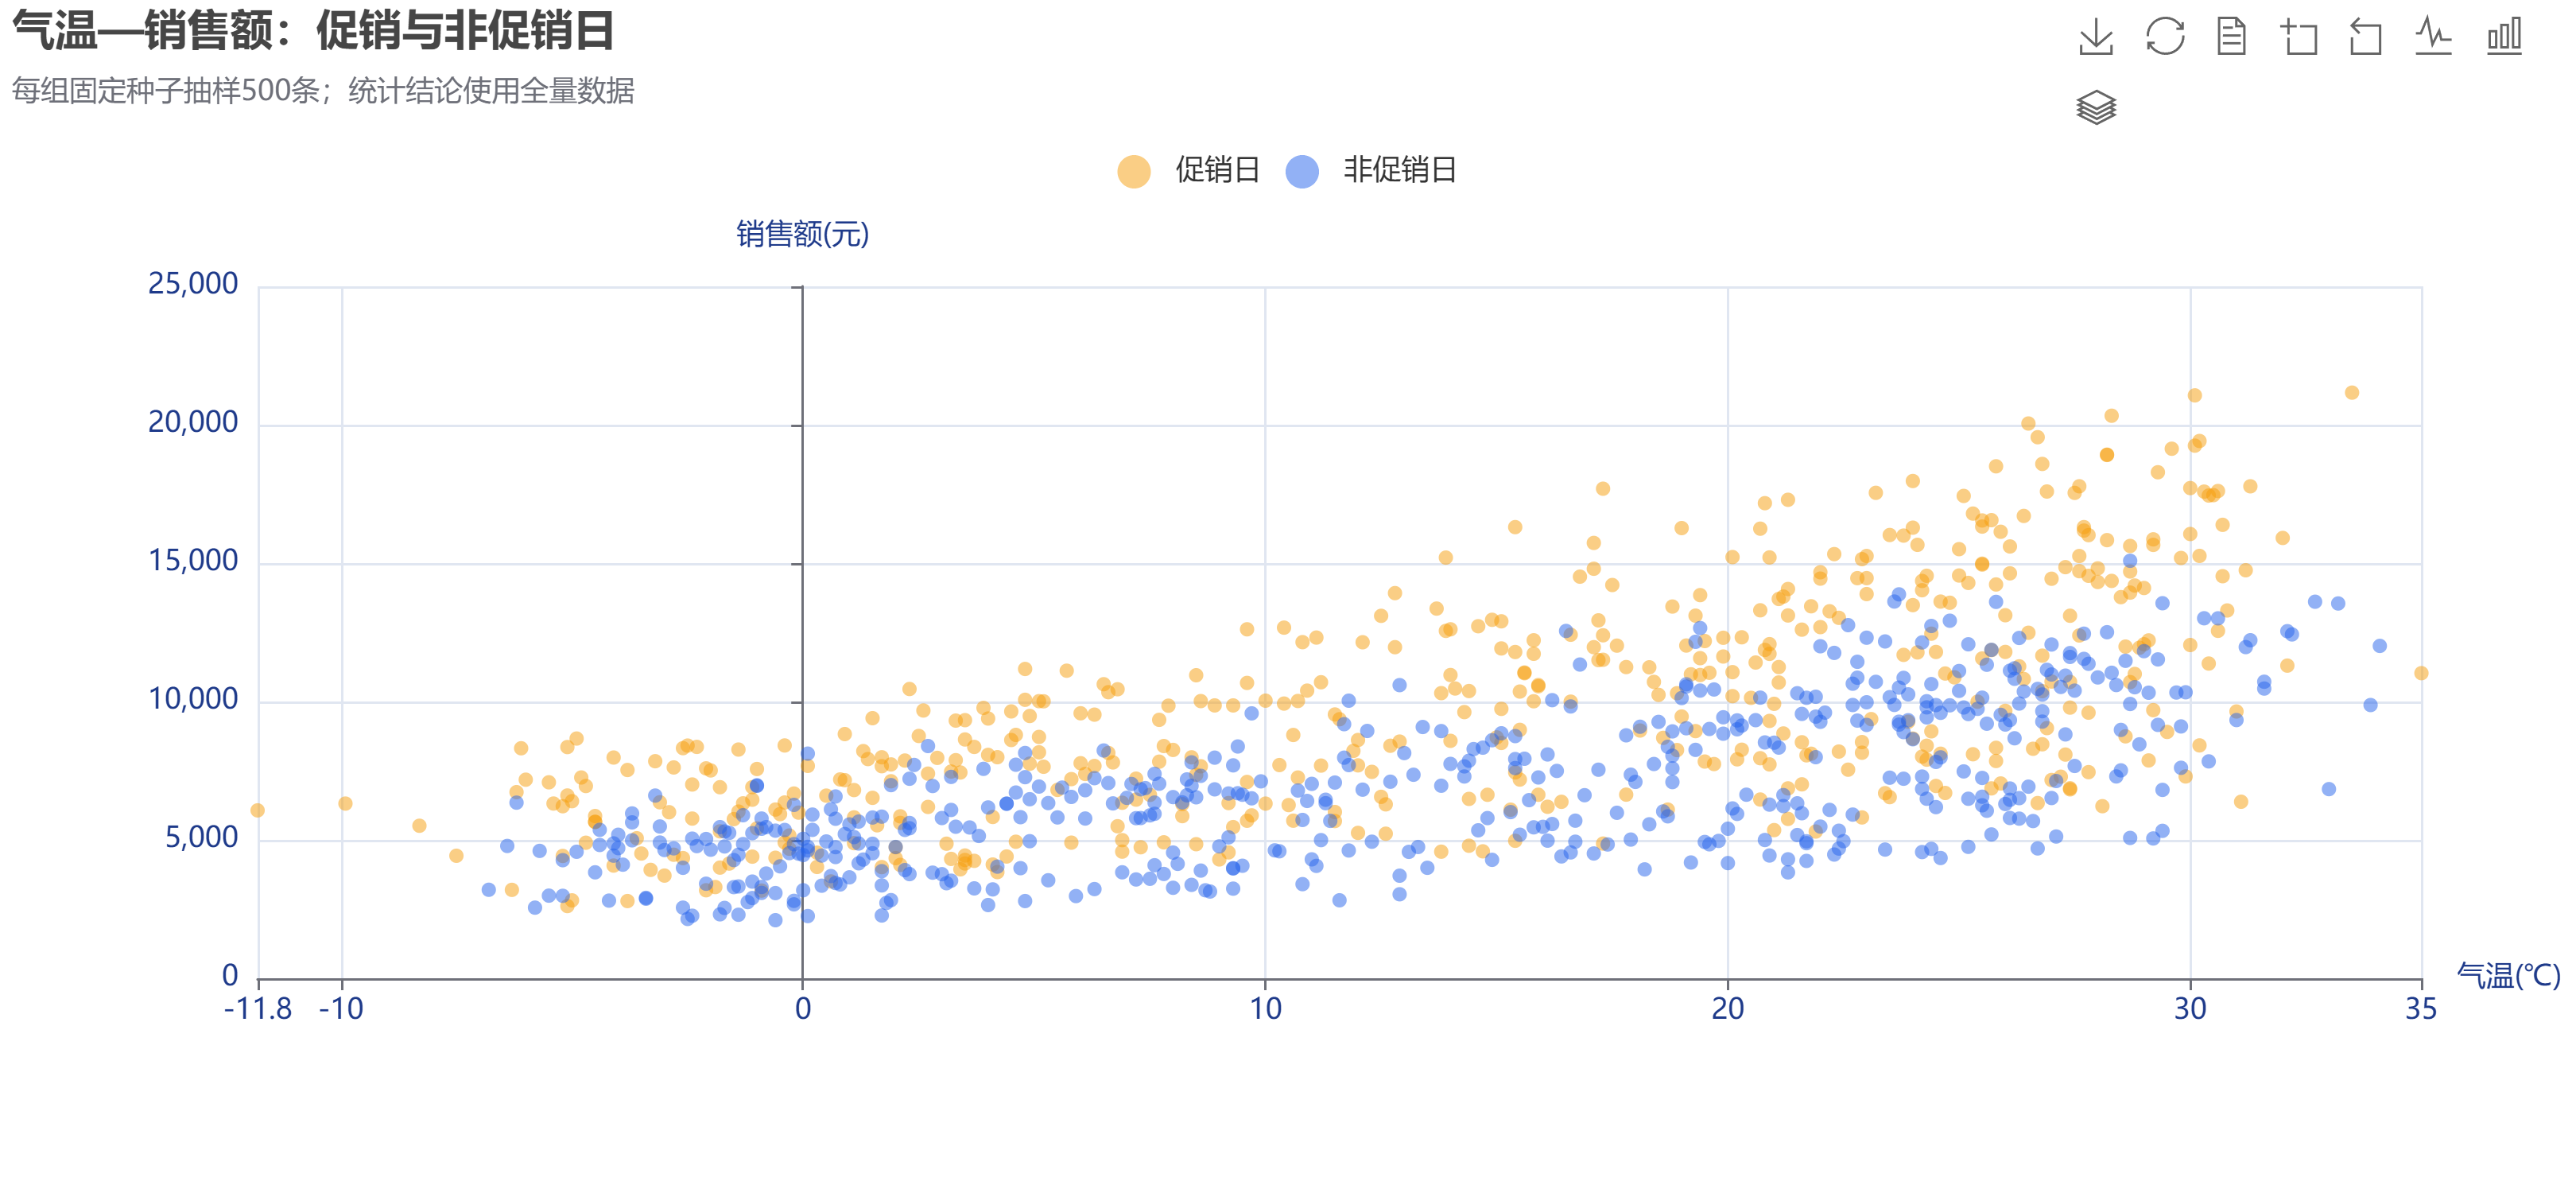

,count,mean,median
是否促销,,,
否,2417,6934.03,6506.5
是,503,9820.45,8929.7


促销日均值相对差：41.63%


In [9]:
# 分组固定种子各抽500条，确保两组样本量相当；全量分析仍使用原始df。
samples = {label: df.loc[df['是否促销'].eq(flag)].sample(n=500, random_state=42)
           for label, flag in [('促销日', '是'), ('非促销日', '否')]}
sc = Scatter(init_opts=init('气温与销售额'))
# 不共用两组x序列，直接传入独立[x,y]点对，避免把非促销y错配到促销x上。
sc.add_xaxis([])
for label, color in [('促销日', AMBER), ('非促销日', BLUE)]:
    points = samples[label][['气温', '销售额']].to_numpy().tolist()
    sc.add_yaxis(label, points, symbol_size=6,
                  label_opts=opts.LabelOpts(is_show=False),
                  itemstyle_opts=opts.ItemStyleOpts(color=color, opacity=.5))
sc.set_global_opts(
    title_opts=opts.TitleOpts(title='气温—销售额：促销与非促销日', subtitle='每组固定种子抽样500条；统计结论使用全量数据'),
    legend_opts=opts.LegendOpts(pos_top='12%'),
    tooltip_opts=opts.TooltipOpts(trigger='item', formatter='{a}<br/>[气温(℃), 销售额(元)]：{c}'),
    xaxis_opts=opts.AxisOpts(type_='value', name='气温(℃)', min_='dataMin', max_='dataMax'),
    yaxis_opts=opts.AxisOpts(type_='value', name='销售额(元)'),
    toolbox_opts=opts.ToolboxOpts(is_show=True, feature=opts.ToolBoxFeatureOpts(
        data_zoom=opts.ToolBoxFeatureDataZoomOpts(),
        restore=opts.ToolBoxFeatureRestoreOpts(),
        save_as_image=opts.ToolBoxFeatureSaveAsImageOpts(pixel_ratio=3))))
export_chart(sc, 'p4_scatter.html')
promo_stats = df.groupby('是否促销')['销售额'].agg(['count', 'mean', 'median'])
display(promo_stats.round(2))
print(f'促销日均值相对差：{(promo_stats.loc["是","mean"] / promo_stats.loc["否","mean"] - 1):.2%}')

### T8 简要分析
全量数据中促销门店日共 503 条，非促销 2,417 条，日均销售额分别为 9,820.45 元和 6,934.03 元，促销组高约 41.63%。散点仅各抽样 500 条用于可读性，不用抽样均值代替全量统计。橙点整体偏高且两组均随气温升高上移，框选缩放与悬停可进一步定位高温高销售等极端点。该差异未控制季节、门店、天气等混杂因素，只能称“组间观察差异”，不能称为促销带来的净增幅；两组点对已独立保留，不能让它们共用一组气温坐标。

## 综合任务　暖暖咖啡运营数据故事看板

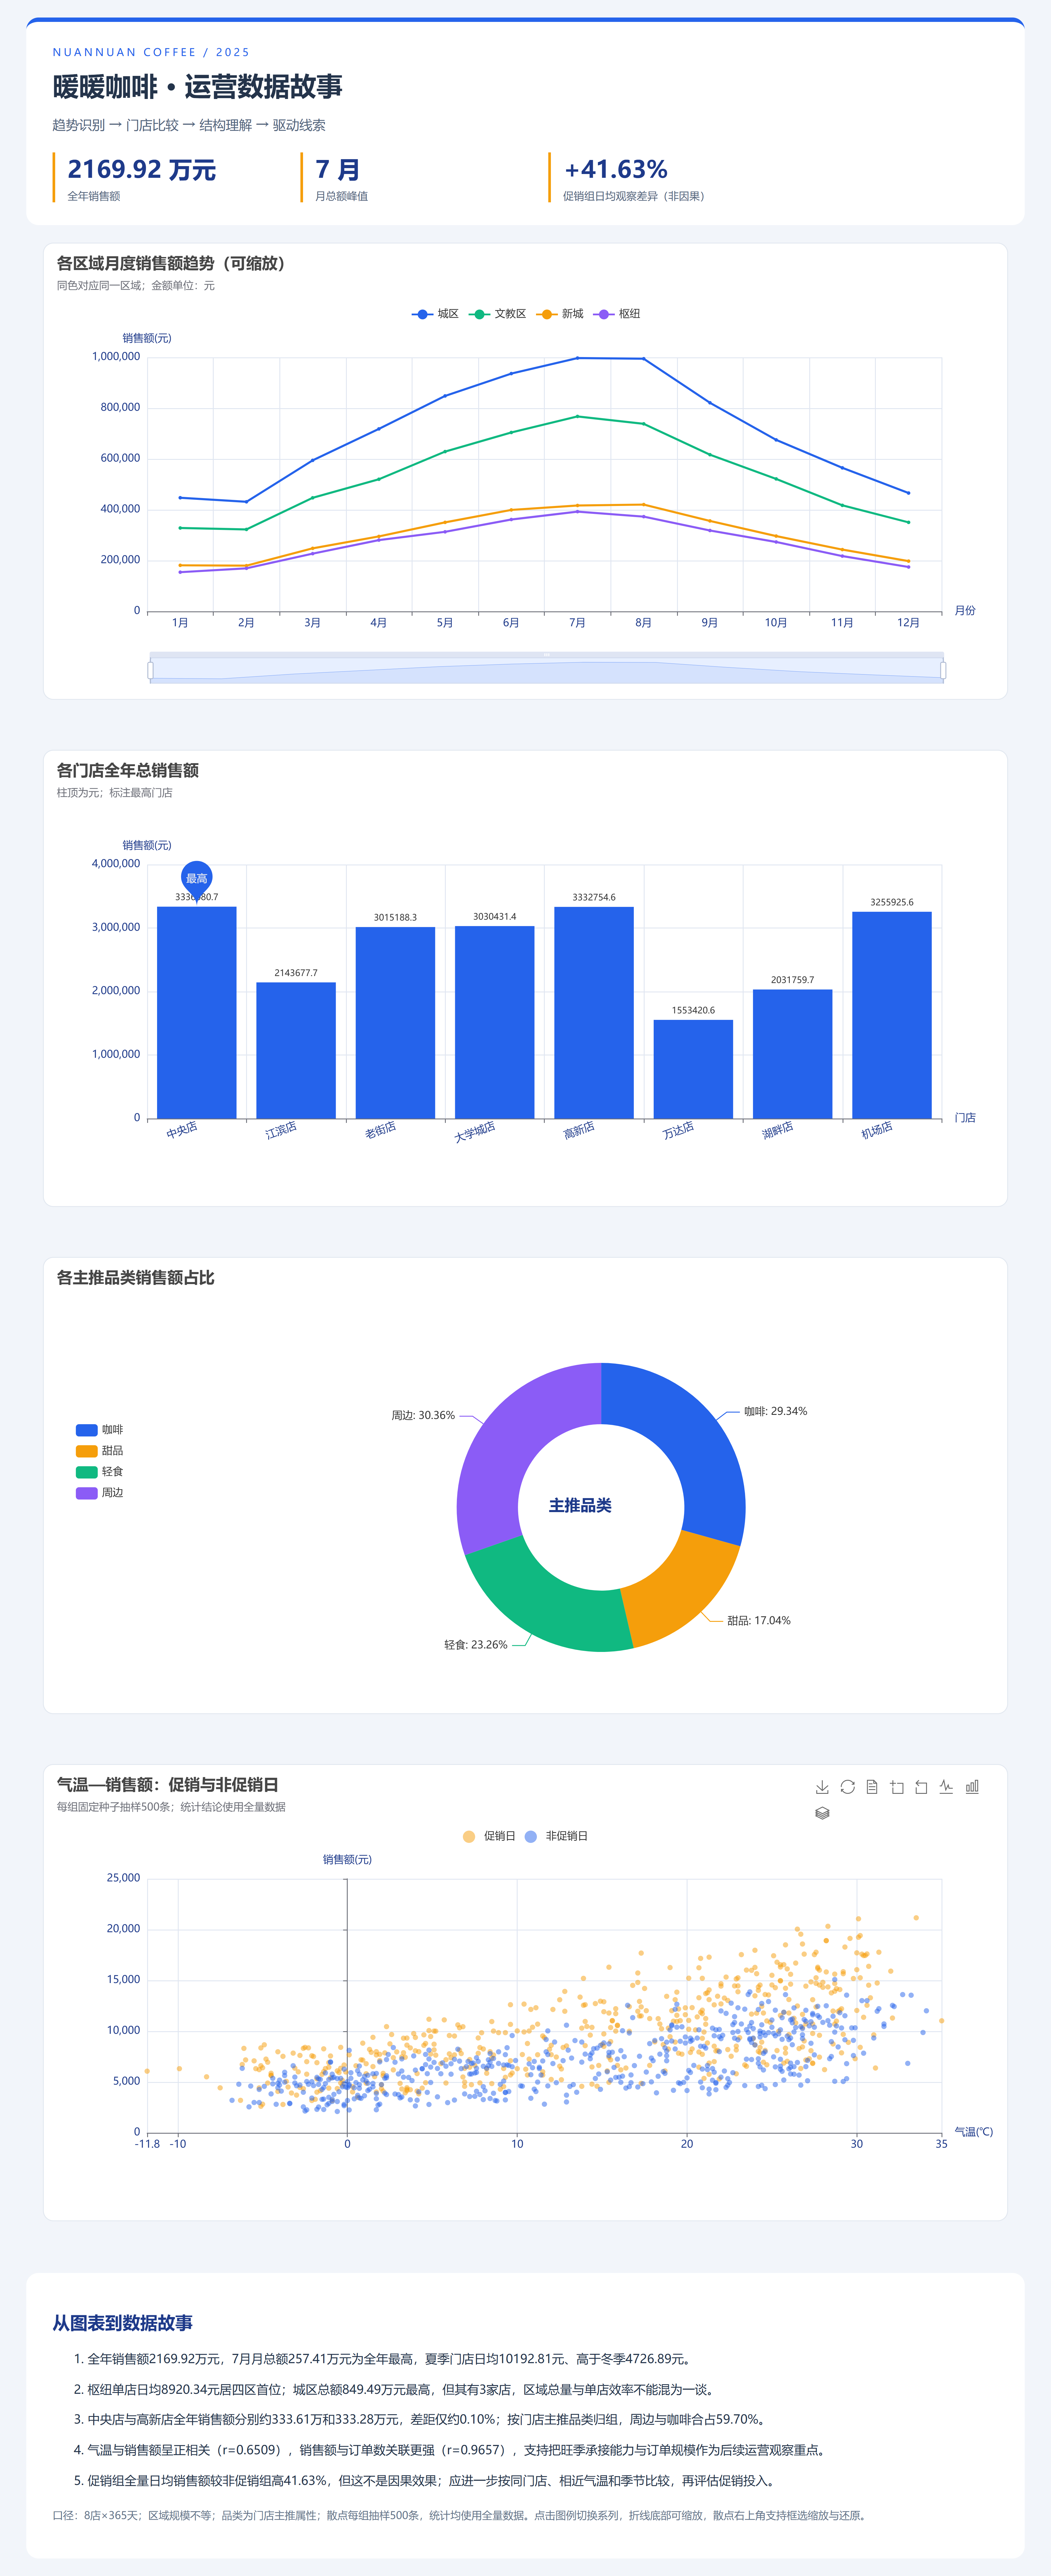

静态探索：各季节门店日均与总额（不能将季节总额直接作为效率指标）


,count,mean,sum
季节,,,
春,736,7434.71,5471950.2
夏,736,10192.81,7501905.8
秋,728,7310.47,5322020.4
冬,720,4726.89,3403362.2


1. 全年销售额2169.92万元，7月月总额257.41万元为全年最高，夏季门店日均10192.81元、高于冬季4726.89元。
2. 枢纽单店日均8920.34元居四区首位；城区总额849.49万元最高，但其有3家店，区域总量与单店效率不能混为一谈。
3. 中央店与高新店全年销售额分别约333.61万和333.28万元，差距仅约0.10%；按门店主推品类归组，周边与咖啡合占59.70%。
4. 气温与销售额呈正相关（r=0.6509），销售额与订单数关联更强（r=0.9657），支持把旺季承接能力与订单规模作为后续运营观察重点。
5. 促销组全量日均销售额较非促销组高41.63%，但这不是因果效果；应进一步按同门店、相近气温和季节比较，再评估促销投入。


In [10]:
# Page组合四类图；沿用前述同一数据与图表对象，口径和配色不变。
page = Page(page_title='暖暖咖啡 · 2025运营数据故事', layout=Page.SimplePageLayout)
page.add(line, bar, pie, sc)
dashboard = offline_html(page.render_embed())
# 页面从趋势→门店→结构→解释变量组织，不把多个无关图简单拼贴。
story = [
    '全年销售额2169.92万元，7月月总额257.41万元为全年最高，夏季门店日均10192.81元、高于冬季4726.89元。',
    '枢纽单店日均8920.34元居四区首位；城区总额849.49万元最高，但其有3家店，区域总量与单店效率不能混为一谈。',
    '中央店与高新店全年销售额分别约333.61万和333.28万元，差距仅约0.10%；按门店主推品类归组，周边与咖啡合占59.70%。',
    '气温与销售额呈正相关（r=0.6509），销售额与订单数关联更强（r=0.9657），支持把旺季承接能力与订单规模作为后续运营观察重点。',
    '促销组全量日均销售额较非促销组高41.63%，但这不是因果效果；应进一步按同门店、相近气温和季节比较，再评估促销投入。'
]
header = '<header><div class="eyebrow">NUANNUAN COFFEE / 2025</div><h1>暖暖咖啡 · 运营数据故事</h1><p>趋势识别 → 门店比较 → 结构理解 → 驱动线索</p><section class="kpis"><div><strong>2169.92 万元</strong><span>全年销售额</span></div><div><strong>7 月</strong><span>月总额峰值</span></div><div><strong>+41.63%</strong><span>促销组日均观察差异（非因果）</span></div></section></header>'
footer = '<section class="story"><h2>从图表到数据故事</h2><ol>' + ''.join('<li>'+s+'</li>' for s in story) + '</ol><p class="note">口径：8店×365天；区域规模不等；品类为门店主推属性；散点每组抽样500条，统计均使用全量数据。点击图例切换系列，折线底部可缩放，散点右上角支持框选缩放与还原。</p></section>'
style = """
<style>
body{margin:0;background:#F2F5FA;color:#24344B;font-family:'Microsoft YaHei',sans-serif;}
header,.story{box-sizing:border-box;width:1140px;margin:20px auto;padding:26px 30px;background:white;border-radius:14px;}
header{border-top:5px solid #2563EB;} h1{font-size:30px;margin:10px 0;}h2{font-size:20px;color:#1E3A8A;}
.eyebrow{font-size:12px;letter-spacing:3px;color:#2563EB;}header p{font-size:15px;color:#52647C;}
.kpis{display:flex;gap:36px;margin-top:22px;}.kpis div{min-width:230px;border-left:3px solid #F59E0B;padding-left:14px;}
.kpis strong{display:block;font-size:27px;color:#1E3A8A;}.kpis span{display:block;font-size:12px;margin-top:5px;color:#52647C;}
.box{display:flex!important;flex-direction:column;align-items:center;gap:18px;width:1140px!important;margin:0 auto;}
.chart-container{border:1px solid #E2E8F0!important;border-radius:12px;padding:10px;background:white;box-sizing:content-box;}
.story li{font-size:14px;line-height:1.9;margin:8px 0;}.note{font-size:12px;color:#64748B;line-height:1.8;}
</style>
"""
dashboard = dashboard.replace('</head>', style + '</head>').replace('<body >', '<body>').replace('<body>', '<body>'+header)
dashboard = dashboard.replace('</body>', footer + '</body>')
(OUT / 'dashboard_combo.html').write_text(dashboard, encoding='utf-8')
display(HTML('<a href="dashboard_combo.html" target="_blank">打开综合交互看板 dashboard_combo.html</a>'))
if (OUT / 'dashboard_combo.png').exists():
    display(Image(filename=str(OUT / 'dashboard_combo.png'), width=1000))
print('静态探索：各季节门店日均与总额（不能将季节总额直接作为效率指标）')
display(season_stats.round(2))
for i, sentence in enumerate(story, 1):
    print(f'{i}. {sentence}')

### 综合任务简要分析：静态与交互

T1–T4 通过销售分布、门店差异、气温回归和相关矩阵提供统计洞察；T5–T8 用同一份清洗后的全量数据聚合，组成 `Page` 看板。全店夏季日均销售额最高，冬季最低；总量与单店日均分别回答“规模”和“效率”，不能混用。看板中的五句数据故事把趋势、区域、门店/结构、相关性与促销线索连为一条分析链。

- **Seaborn 静态图**：适合报告、打印和精确对比分布/统计关系；300 dpi PNG 便于归档，缺点是无法通过悬停读取每点细节，拥挤时需要重画。
- **Pyecharts 交互图**：适合浏览器看板、筛选系列和探索局部；DataZoom、图例切换、tooltip、框选缩放帮助发现模式，缺点是依赖浏览器运行，且过滤后需要注意比较口径。
- 本次 HTML 已内嵌运行库与 ROMA 主题；配套 PNG 是同一网页实际渲染的固定快照，含综合看板 300 dpi 版本，便于不支持脚本的查看环境。

## 思考题

### 1．如何用同一份数据同时支撑 Seaborn 统计洞察与 Pyecharts 交互看板？
只读取一份原始 CSV，先统一日期、缺失值与重复记录检查，再复用同一个 `df`。Seaborn 对门店日原始记录绘制分布、回归与相关矩阵；Pyecharts 按月份×区域、门店、主推品类分别聚合，并按促销分组抽样散点。统一字段含义、金额单位、固定色映射和筛选条件。

### 2．何时该选交互式图表？DataZoom / 图例切换解决了什么？
当需要比较多系列、查看局部时段、读取精确数据或定位异常点，选择交互图更方便。DataZoom 缩小横轴可见范围，帮助聚焦旺季或局部波动；图例切换隐藏暂不关注的区域或促销组，减少遮挡。tooltip 补充精确值。

### 3．小提琴图与箱线图各自适合回答什么问题？
小提琴图结合核密度轮廓与内嵌箱体，适合回答销售额是否偏态、是否可能多峰、哪些区间更密集；形状会受样本量和带宽影响。箱线图以中位数、上下四分位数、须和异常点浓缩分布，更适合快速比较多店的中心、离散程度及离群情况。本数据每店365条记录，适合小提琴观察形状；若只汇报各店典型水平和波动，箱线图更简洁。

### 4．综合看板中，怎样用图表“讲故事”而非堆图？
先提出“何时旺、哪里强、收入来自哪些门店结构、哪些变量值得追查”的连续问题，再按折线→柱状→圆环→散点排列。折线确定夏季旺季；门店柱状找到中央与高新两家近似领先店；圆环说明门店主推品类构成；散点结合回归提示气温与促销线索。每张图配具体数字、统计单位与边界，并让结论导向可执行的下一步：旺季备货和排班、同店同季条件下比较促销。